# Análisis de riesgo de préstamos — Banco checo

**Objetivo:** entender qué características tienen los préstamos que salen mal.

**Datos:** dataset Berka (PKDD'99), con datos reales y anonimizados de un banco checo entre 1993 y 1998. Los importes están en coronas checas.

**Tablas que uso:**
- `loan`: préstamos (importe, duración, cuota y estado)
- `account`: cuentas (sirve para unir cada préstamo con su distrito)
- `district`: distritos (nombre, región y datos socioeconómicos)

**Columnas de `district` que uso:** en los datos originales tienen nombres codificados (`A1` a `A16`). Estas son las que aparecen en el análisis:

| Columna | Significado |
|---|---|
| `A1` | Identificador del distrito (se une con `district_id` de `account`) |
| `A2` | Nombre del distrito |
| `A3` | Región |

**Estados del préstamo:**

| status | Significado | Tipo |
|---|---|---|
| A | Terminado y pagado | Bueno |
| B | Terminado y sin pagar | Malo |
| C | En curso y al día | Bueno |
| D | En curso con deudas | Malo |

El diccionario completo de las 8 tablas está en [diccionario_datos.md](diccionario_datos.md).

## 1. Carga de los datos

Leo los 8 archivos CSV de la carpeta `data/` (van separados por punto y coma) y los guardo en un diccionario, con el nombre de cada tabla como clave. Al final compruebo el tamaño de cada una (filas, columnas).

In [107]:
import pandas as pd
from pathlib import Path
tablas={}

for archivo in Path ("data").glob("*.csv"):
    nombre=archivo.stem
    tablas[nombre]=pd.read_csv(archivo, sep=";",low_memory=False)
    print(nombre,tablas[nombre].shape)
    

account (4500, 4)
card (892, 4)
client (5369, 3)
disp (5369, 4)
district (77, 16)
loan (682, 7)
order (6471, 6)
trans (1056320, 10)


Guardo las 8 tablas en una base de datos SQLite (`banco.db`) para poder consultarlas con SQL.

La tabla `order` se guarda como `orders`, porque `ORDER` es una palabra reservada de SQL y daría errores en las consultas.

In [27]:
import sqlite3
conexion=sqlite3.connect("banco.db")
for nombre, df in tablas.items():
    if nombre=="order":
        nombre="orders"
    df.to_sql(nombre, conexion, if_exists="replace", index=False)
    print(nombre, "cargada en la base de datos")


account cargada en la base de datos
card cargada en la base de datos
client cargada en la base de datos
disp cargada en la base de datos
district cargada en la base de datos
loan cargada en la base de datos
orders cargada en la base de datos
trans cargada en la base de datos


Compruebo que la base de datos funciona echando un vistazo a una de las tablas (órdenes permanentes).

In [32]:
pd.read_sql("SELECT * FROM orders LIMIT 10", conexion)

,order_id,account_id,bank_to,account_to,amount,k_symbol
0,29401,1,YZ,87144583,2452.0,SIPO
1,29402,2,ST,89597016,3372.7,UVER
2,29403,2,QR,13943797,7266.0,SIPO
3,29404,3,WX,83084338,1135.0,SIPO
4,29405,3,CD,24485939,327.0,
5,29406,3,AB,59972357,3539.0,POJISTNE
6,29407,4,UV,26693541,2078.0,SIPO
7,29408,4,UV,5848086,1285.0,SIPO
8,29409,5,GH,37390208,2668.0,SIPO
9,29410,6,AB,44486999,3954.0,SIPO


## 2. ¿Cómo se reparten los préstamos?

Cuento cuántos préstamos hay en cada estado (A, B, C o D).

In [35]:
consulta="""
SELECT status, COUNT(*) AS num_prestamos
FROM loan
GROUP BY status
"""
pd.read_sql(consulta, conexion)

,status,num_prestamos
0,A,203
1,B,31
2,C,403
3,D,45


**Conclusión:** de los 682 préstamos, 606 son buenos (A + C = 88,9 %) y 76 son malos (B + D = 11,1 %). Es decir, más o menos **1 de cada 9 préstamos sale mal**.

Este **11,1 %** es la cifra de referencia para comparar el resto del análisis.

## 3. ¿Influye el importe del préstamo?

Empiezo mirando los préstamos grandes, de más de 400.000 coronas.

In [125]:
pd.read_sql("SELECT loan_id, amount, status FROM loan WHERE amount>400000", conexion)

,loan_id,amount,status
0,6228,464520,B
1,7142,482940,D
2,5132,538500,C
3,6704,417060,C
4,5970,465072,C
5,7304,419880,C
6,5725,444864,C
7,5938,402000,C
8,7101,421008,C
9,7154,417600,C


**Observación:** hay 26 préstamos de más de 400.000 coronas. Ninguno está en estado A y 7 son malos (B o D): 7 / 26 = **26,9 %**, más del doble que la media del banco (11,1 %).

Que no haya ningún A tiene sentido: los préstamos grandes suelen pedirse a más años, así que casi ninguno había terminado cuando se cerraron los datos (1998).

In [90]:
pd.read_sql("SELECT loan_id, amount, status FROM loan ORDER BY amount ASC LIMIT 5",conexion)

,loan_id,amount,status
0,5657,4980,A
1,6234,5148,C
2,6699,7656,A
3,6688,8616,C
4,6312,10944,C


In [57]:
pd.read_sql("SELECT COUNT (*)  FROM loan WHERE status='A'", conexion)

,COUNT (*)
0,203


203 de 682 = **29,8 %** de los préstamos ya se han terminado de pagar sin problemas.

In [63]:
pd.read_sql("SELECT status, COUNT(*) AS num_prestamos FROM loan GROUP BY status", conexion)

,status,num_prestamos
0,A,203
1,B,31
2,C,403
3,D,45


In [91]:
pd.read_sql("SELECT * FROM loan LIMIT 5", conexion)

,loan_id,account_id,date,amount,duration,payments,status
0,5314,1787,930705,96396,12,8033.0,B
1,5316,1801,930711,165960,36,4610.0,A
2,6863,9188,930728,127080,60,2118.0,A
3,5325,1843,930803,105804,36,2939.0,A
4,7240,11013,930906,274740,60,4579.0,A


Para comprobarlo con todos los préstamos, y no solo con unos pocos, calculo el **importe medio** de cada estado.

In [86]:
medias =pd.read_sql("SELECT  status, AVG(amount) AS promedio FROM loan GROUP BY status", conexion)    
pd.read_sql("SELECT  status, AVG(amount) AS promedio FROM loan GROUP BY status", conexion)    


,status,promedio
0,A,91641.458128
1,B,140720.903226
2,C,171410.352357
3,D,249284.533333


<Axes: title={'center': 'Promedio de monto por estado del préstamo'}, xlabel='status'>

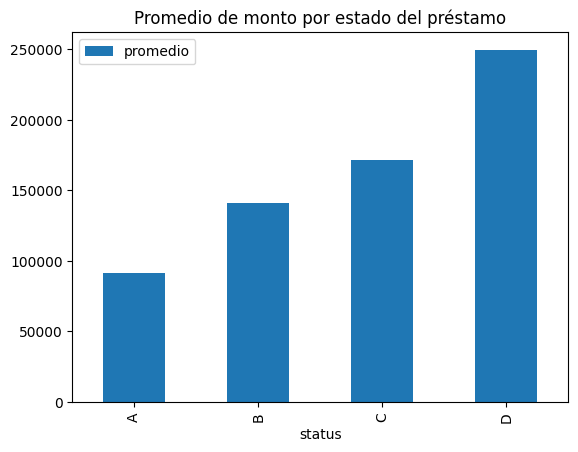

In [87]:
medias.plot.bar(x="status", y="promedio", title="Promedio de monto por estado del préstamo")

**Conclusión:** hay que comparar préstamos que están en la misma situación:

- **Terminados:** los impagados (B, 140.721 de media) son un **54 % más grandes** que los pagados (A, 91.641).
- **En curso:** los que tienen deudas (D, 249.285) son un **45 % más grandes** que los que van al día (C, 171.410).

En los dos casos, **los préstamos que salen mal son de media alrededor de 1,5 veces más grandes**. El importe es una señal de riesgo: cuanto más grande es el préstamo, más motivos hay para revisarlo con cuidado antes de concederlo.

<Axes: title={'center': 'Cantidad de préstamos por estado'}, xlabel='status'>

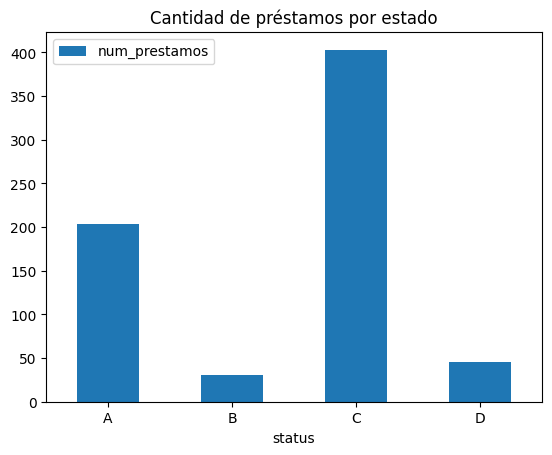

In [98]:
conteo=pd.read_sql("SELECT status, COUNT(*) AS num_prestamos FROM loan GROUP BY status", conexion)
conteo.plot.bar(x="status", y="num_prestamos", title="Cantidad de préstamos por estado",rot=0)

**Conclusión:** en número, los préstamos malos (B y D) son los más escasos; en importe medio, son los más grandes. Hay **pocos préstamos malos, pero cada uno es grande**.

Calculando el dinero de cada estado (número × importe medio):

- Préstamos malos: 31 × 140.721 + 45 × 249.285 = **15.580.152** coronas
- Todos los préstamos: **103.261.739** coronas
- 15.580.152 / 103.261.739 = **15,1 %**

Los préstamos malos son el 11,1 % de los préstamos, pero el **15,1 % del dinero prestado**. Para el banco, el problema pesa más en dinero que en número.

## 4. ¿Influye la región?

La tabla `loan` no sabe dónde está el cliente. Para saberlo hay que unir tablas: **préstamo → cuenta → distrito**.

Primero uno `loan` con `account`, usando la columna que tienen en común (`account_id`). Así cada préstamo tiene al lado el distrito de su cuenta.

In [101]:
pd.read_sql("""
SELECT loan.loan_id, loan.status, account.district_id
FROM loan
JOIN account ON loan.account_id=account.account_id
limit 5
""", conexion)

,loan_id,status,district_id
0,5314,B,30
1,5316,A,46
2,6863,A,45
3,5325,A,12
4,7240,A,1


Vistazo a la tabla `district`. Sus columnas tienen nombres codificados (`A1` a `A16`); su significado está en la introducción y en el diccionario de datos.

In [124]:
pd.read_sql("SELECT * FROM district LIMIT 1", conexion)

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12,A13,A14,A15,A16
0,1,Hl.m. Praha,Prague,1204953,0,0,0,1,1,100.0,12541,0.29,0.43,167,85677,99107


Añado un segundo JOIN con `district` (`account.district_id = district.A1`), para que cada préstamo tenga su distrito (`A2`) y su región (`A3`).

In [105]:
pd.read_sql("""
SELECT loan.loan_id, loan.status, district.A2, district.A3
FROM loan
JOIN account ON loan.account_id = account.account_id
JOIN district ON account.district_id = district.A1
LIMIT 5
""", conexion)

,loan_id,status,A2,A3
0,5314,B,Sokolov,west Bohemia
1,5316,A,Nachod,east Bohemia
2,6863,A,Jicin,east Bohemia
3,5325,A,Pribram,central Bohemia
4,7240,A,Hl.m. Praha,Prague


Cuento cuántos préstamos hay en cada región.

Agrupo por región (`A3`) y no por distrito (`A2`): hay 77 distritos y algunos tienen solo 1 o 2 préstamos, así que cualquier porcentaje calculado sobre ellos no sería fiable.

In [109]:
pd.read_sql("""
SELECT district.A3, COUNT(*) AS num_prestamos
FROM loan
JOIN account ON loan.account_id = account.account_id
JOIN district ON account.district_id = district.A1
GROUP BY district.A3
ORDER BY num_prestamos DESC
""", conexion)

,A3,num_prestamos
0,south Moravia,129
1,north Moravia,117
2,central Bohemia,90
3,east Bohemia,84
4,Prague,84
5,north Bohemia,61
6,south Bohemia,60
7,west Bohemia,57


Los totales suman 682, así que no se ha perdido ningún préstamo al unir las tablas. Todas las regiones tienen al menos 57 préstamos, suficientes para calcular porcentajes.

Ahora cuento solo los préstamos impagados (estados B y D) de cada región.

In [117]:
pd.read_sql("""
SELECT district.A3, COUNT(*) AS prestamos_impagados
FROM loan
JOIN account ON loan.account_id = account.account_id
JOIN district ON account.district_id = district.A1
WHERE loan.status in ('B','D')
GROUP BY district.A3
ORDER BY prestamos_impagados DESC
""", conexion)

,A3,prestamos_impagados
0,north Moravia,18
1,south Moravia,13
2,central Bohemia,10
3,west Bohemia,9
4,south Bohemia,9
5,east Bohemia,9
6,Prague,7
7,north Bohemia,1


El número de impagados por sí solo engaña: una región con más préstamos tendrá también más impagados. Para comparar de forma justa hace falta el **porcentaje**.

Con `CASE WHEN` cuento en una sola consulta el total y los impagados de cada región: pone un 1 a cada préstamo B o D y un 0 al resto, y `SUM` suma esos unos.

In [121]:
regiones = pd.read_sql("""
SELECT district.A3 AS region,
COUNT(*) AS num_prestamos,
SUM(CASE WHEN loan.status IN ('B','D') THEN 1 ELSE 0 END) AS prestamos_IMPAGADOS
FROM loan
JOIN account ON loan.account_id = account.account_id
JOIN district ON account.district_id = district.A1
GROUP BY district.A3
""", conexion)

Con pandas calculo la tasa de impago de cada región: impagados / total × 100.

In [122]:
regiones["tasa_impago"] = regiones["prestamos_IMPAGADOS"] / regiones["num_prestamos"] * 100

regiones.sort_values("tasa_impago", ascending=False)

,region,num_prestamos,prestamos_IMPAGADOS,tasa_impago
7,west Bohemia,57,9,15.789474
4,north Moravia,117,18,15.384615
5,south Bohemia,60,9,15.000000
1,central Bohemia,90,10,11.111111
2,east Bohemia,84,9,10.714286
6,south Moravia,129,13,10.077519
0,Prague,84,7,8.333333
3,north Bohemia,61,1,1.639344


Tasa de impago por región. La línea roja marca la media del banco (11,1 %).

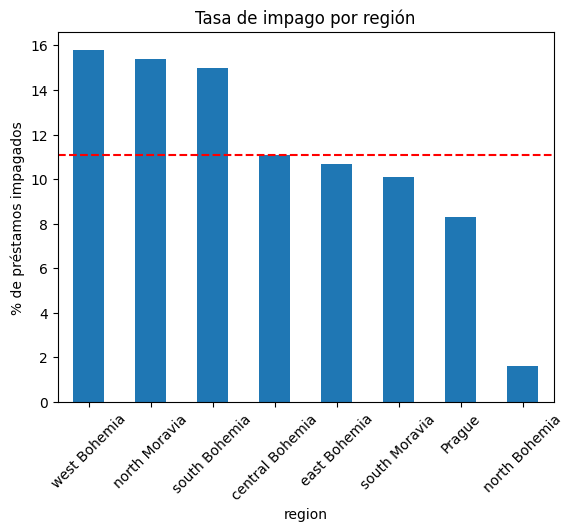

In [123]:
regiones["tasa_impago"] = regiones["tasa_impago"].round(1)
regiones = regiones.sort_values("tasa_impago", ascending=False)

ax = regiones.plot.bar(x="region", y="tasa_impago", legend=False, rot=45,
                       title="Tasa de impago por región", ylabel="% de préstamos impagados")
ax.axhline(11.1, color="red", linestyle="--");

## Conclusiones generales

1. **El 11,1 % de los préstamos sale mal** (76 de 682), pero esos préstamos suponen el **15,1 % del dinero prestado**.
2. **El importe es una señal de riesgo:** los préstamos que salen mal son de media alrededor de 1,5 veces más grandes que los que salen bien.
3. **La región también importa:** west Bohemia, north Moravia y south Bohemia tienen una tasa de impago de alrededor del 15 %, frente al 8,3 % de Praga.

**Limitaciones:**
- Son pocos préstamos (682), así que algunos resultados, como el 1,6 % de north Bohemia, pueden deberse en parte a la casualidad.
- Muchos préstamos siguen en curso (C y D), así que todavía no se sabe cómo terminarán.

**Próximos pasos:**
- Comprobar si el salario medio (`A11`) o el paro (`A13`) de cada distrito explican las diferencias entre regiones.
- Convertir las fechas (formato AAMMDD) para analizar la evolución en el tiempo.
- Construir un modelo sencillo que prediga qué préstamos tienen más riesgo de impago.